# Predicting Sediment Particle Size Distributions with Machine Learning
**UE24CS352A – Machine Learning | Mini-Project**

Random Forest (RF) and Support Vector Regression (SVR) are used to predict the **median particle diameter (d50)** and **PSD variance (σ²)** of suspended marine sediment from water-quality and hydrodynamic measurements. The task follows Egan, *"Machine learning for predicting sediment particle size distributions"*.

## 1. Problem statement
Particle settling velocity, a key input to sediment-transport models, depends on particle size, which changes over seconds through flocculation. Semi-empirical flocculation models are tuned to specific sites and are hard to generalise. We test whether a data-driven regression model can predict `d50` and `σ²` from eight measured variables.

## 2. Dataset (synthetic)
The original field data (1648 hourly samples from South San Francisco Bay) is not available, so we **generate a synthetic dataset** with the same eight predictors and two targets as the paper.

| Feature | Meaning | Range |
|---|---|---|
| `salinity` | water salinity S (ppt) | 5 – 35 |
| `wave_velocity` | near-bottom wave-induced velocity u_b (m/s) | 0.01 – 0.50 |
| `refractive_index` | particle index of refraction n_p | 1.05 – 1.25 |
| `temperature` | water temperature T (°C) | 5 – 30 |
| `algal_peak_ratio` | a676/a650 (organic peak) | 0.70 – 1.50 |
| `chlorophyll_a` | chl-a, organic-content proxy | 0.1 – 20 |
| `detrital_peak_ratio` | a450/a676 (inorganic peak) | 0.50 – 2.00 |
| `tidal_velocity` | mean tidal velocity ū (m/s) | 0.01 – 1.00 |

Targets `d50` (µm) and `psd_variance` (µm²) are **illustrative functions of the features plus Gaussian noise**. They are *not* validated sediment physics, so the scores below show that the pipeline works, not that it predicts real flocculation.

## 3. Approach
1. Generate and explore the data.
2. Hold out a 20 % test set that is touched only once, at the end.
3. Rank features with RF importance (impurity and permutation) and keep the top 4, as in the paper.
4. Tune RF (number of trees via the out-of-bag score) and SVR (`C`, `ε`, `γ` via 5-fold CV) on the training set only.
5. Evaluate on the test set with R², MAE and RMSE, then run a 5-fold CV check and compare against the theoretical noise ceiling.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_validate
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
os.makedirs("data", exist_ok=True)
os.makedirs("results", exist_ok=True)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})

## 4. Synthetic data generation
Each feature is drawn independently and uniformly. Targets combine linear terms, interaction terms (`salinity × temperature`, `wave_velocity × salinity`) and a quadratic term, plus Gaussian noise (σ = 12 µm for d50, σ = 8 µm² for variance). The noise sets a **maximum achievable R²** (the *noise ceiling*), which we use in Section 9 to judge the models.

In [2]:
N = 5000
NOISE_D50, NOISE_VAR = 12.0, 8.0

salinity            = np.random.uniform(5, 35, N)
wave_velocity       = np.random.uniform(0.01, 0.50, N)
refractive_index    = np.random.uniform(1.05, 1.25, N)
temperature         = np.random.uniform(5, 30, N)
algal_peak_ratio    = np.random.uniform(0.70, 1.50, N)
chlorophyll_a       = np.random.uniform(0.1, 20, N)
detrital_peak_ratio = np.random.uniform(0.50, 2.00, N)
tidal_velocity      = np.random.uniform(0.01, 1.00, N)

# Noise-free signals (illustrative relationships, NOT validated sediment equations)
d50_clean = (40 + 3.5*salinity + 100*wave_velocity + 180*(refractive_index - 1.05)
             + 1.2*temperature + 5*algal_peak_ratio + 0.6*chlorophyll_a
             + 2*detrital_peak_ratio + 8*tidal_velocity
             + 0.12*salinity*temperature - 12*wave_velocity*salinity)

var_clean = (15 + 1.8*salinity + 90*wave_velocity + 100*(refractive_index - 1.05)
             + 0.8*temperature + 3*algal_peak_ratio + 0.3*chlorophyll_a
             + 1.5*detrital_peak_ratio + 12*tidal_velocity
             + 0.08*salinity*temperature + 35*wave_velocity**2)

d50          = d50_clean + np.random.normal(0, NOISE_D50, N)
psd_variance = var_clean + np.random.normal(0, NOISE_VAR, N)

# Sizes and variances must be positive (check whether clipping is ever needed)
print("d50 values below 10:", int((d50 < 10).sum()), "| variance values below 1:", int((psd_variance < 1).sum()))
d50 = np.clip(d50, 10, None)
psd_variance = np.clip(psd_variance, 1, None)

df = pd.DataFrame({
    "salinity": salinity, "wave_velocity": wave_velocity, "refractive_index": refractive_index,
    "temperature": temperature, "algal_peak_ratio": algal_peak_ratio, "chlorophyll_a": chlorophyll_a,
    "detrital_peak_ratio": detrital_peak_ratio, "tidal_velocity": tidal_velocity,
    "d50": d50, "psd_variance": psd_variance,
}).sample(frac=1, random_state=SEED).reset_index(drop=True)

df.to_csv("data/sediment_particle_dataset.csv", index=False)

# Noise ceiling: best R2 any model could reach, i.e. R2 of the true noise-free function vs the noisy target
CEILING = {"d50": r2_score(d50, d50_clean), "psd_variance": r2_score(psd_variance, var_clean)}
print("Dataset saved: data/sediment_particle_dataset.csv  shape =", df.shape)
print("Noise ceiling R2 ->", {k: round(v, 4) for k, v in CEILING.items()})
df.head()

d50 values below 10: 0 | variance values below 1: 0
Dataset saved: data/sediment_particle_dataset.csv  shape = (5000, 10)
Noise ceiling R2 -> {'d50': 0.9303, 'psd_variance': 0.958}


,salinity,wave_velocity,refractive_index,temperature,algal_peak_ratio,chlorophyll_a,detrital_peak_ratio,tidal_velocity,d50,psd_variance
0,19.375456,0.049231,1.226899,22.848886,0.804131,14.599980,1.936588,0.200243,227.471855,131.175435
1,7.153274,0.214550,1.091706,21.307980,0.962041,16.397629,1.646468,0.491802,106.666595,99.770785
2,6.570651,0.408035,1.141010,25.878154,1.383747,14.207202,1.397674,0.530663,166.197386,130.671377
3,15.521354,0.251562,1.119273,24.045327,1.140770,4.468667,1.988843,0.732331,175.455371,150.940234
4,34.698807,0.140186,1.167842,15.812084,1.485128,10.796637,1.879154,0.408265,232.576237,163.352391


## 5. Exploratory data analysis

In [3]:
FEATURES = ["salinity", "wave_velocity", "refractive_index", "temperature",
            "algal_peak_ratio", "chlorophyll_a", "detrital_peak_ratio", "tidal_velocity"]
TARGETS = ["d50", "psd_variance"]

print("Missing values:", int(df.isnull().sum().sum()))
df.describe().round(3).T

Missing values: 0


,count,mean,std,min,25%,50%,75%,max
salinity,5000.0,19.905,8.689,5.000,12.316,20.000,27.443,34.992
wave_velocity,5000.0,0.251,0.140,0.010,0.131,0.248,0.369,0.500
refractive_index,5000.0,1.150,0.058,1.050,1.099,1.149,1.202,1.250
temperature,5000.0,17.692,7.195,5.006,11.568,17.811,23.778,29.998
algal_peak_ratio,5000.0,1.107,0.231,0.700,0.907,1.111,1.306,1.500
chlorophyll_a,5000.0,9.877,5.663,0.102,5.018,9.870,14.670,19.995
detrital_peak_ratio,5000.0,1.251,0.432,0.500,0.871,1.253,1.622,2.000
tidal_velocity,5000.0,0.502,0.287,0.010,0.254,0.503,0.750,0.999
d50,5000.0,174.383,46.462,48.745,141.391,167.355,200.596,370.909
psd_variance,5000.0,143.039,38.249,44.595,114.487,140.702,169.669,272.922


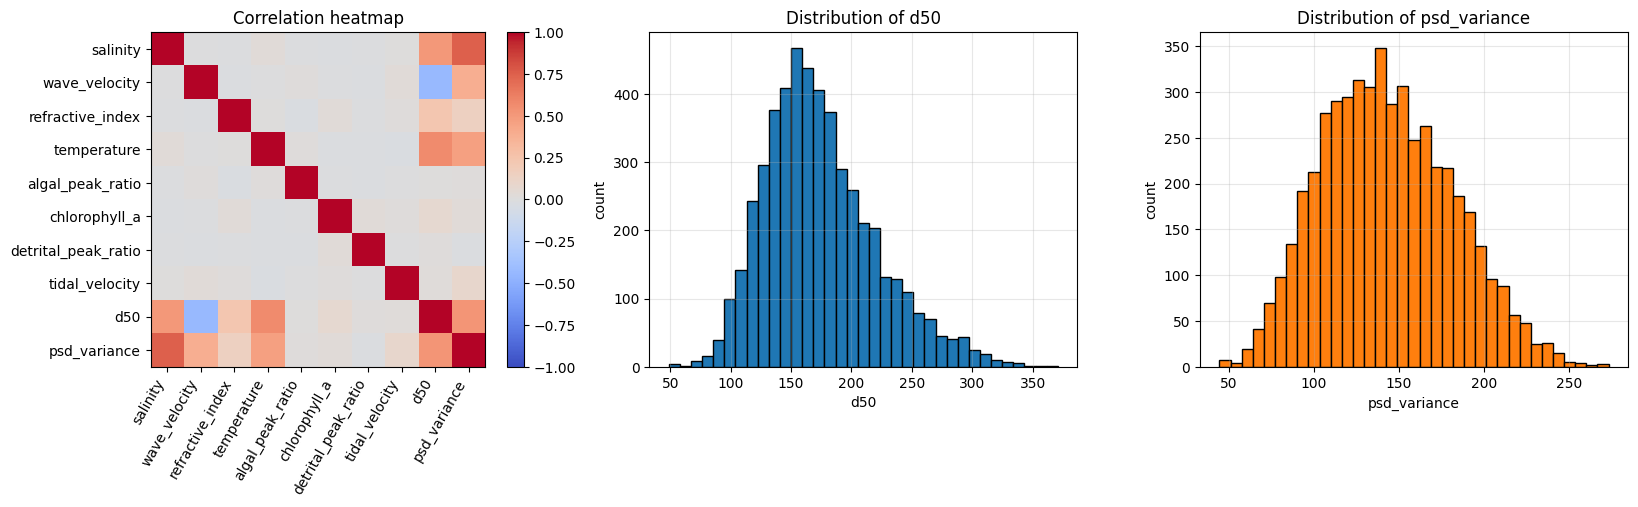

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

corr = df.corr()
im = axes[0].imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
axes[0].set_xticks(range(len(corr))); axes[0].set_xticklabels(corr.columns, rotation=60, ha="right")
axes[0].set_yticks(range(len(corr))); axes[0].set_yticklabels(corr.columns)
axes[0].set_title("Correlation heatmap"); axes[0].grid(False)
fig.colorbar(im, ax=axes[0], fraction=0.046)

for ax, t, c in zip(axes[1:], TARGETS, ["tab:blue", "tab:orange"]):
    ax.hist(df[t], bins=35, color=c, edgecolor="black")
    ax.set_title(f"Distribution of {t}"); ax.set_xlabel(t); ax.set_ylabel("count")
plt.tight_layout(); plt.show()

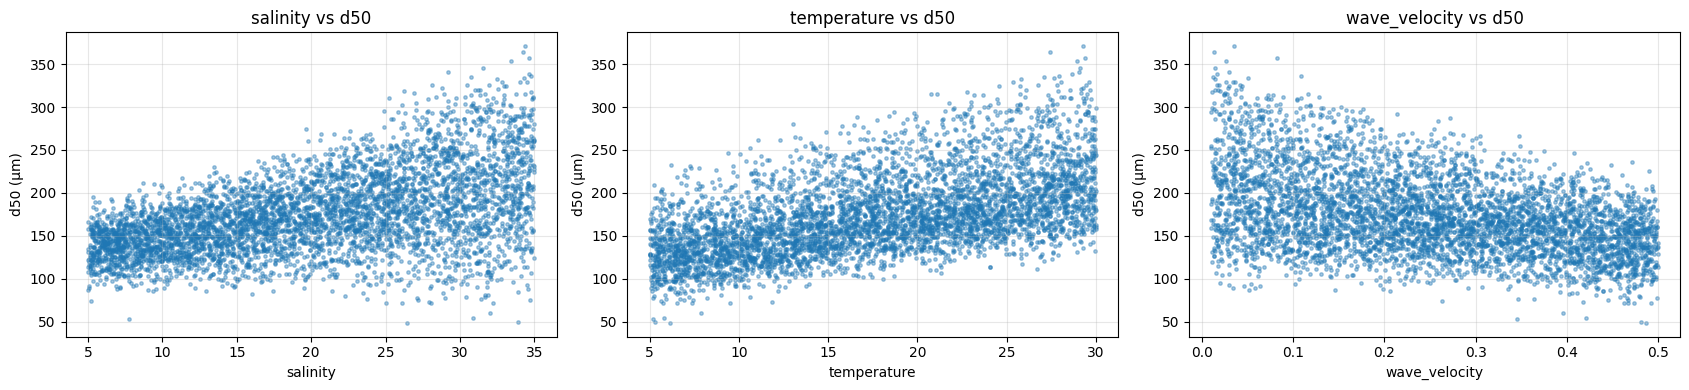

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, f in zip(axes, ["salinity", "temperature", "wave_velocity"]):
    ax.scatter(df[f], df["d50"], s=6, alpha=0.4)
    ax.set_xlabel(f); ax.set_ylabel("d50 (µm)"); ax.set_title(f"{f} vs d50")
plt.tight_layout(); plt.show()

## 6. Train / test split
80 % of the data is used for feature selection and tuning (cross-validation and OOB only), and the remaining 20 % is held out for the final evaluation.

In [6]:
X = df[FEATURES]
X_train, X_test, Y_train, Y_test = train_test_split(X, df[TARGETS], test_size=0.20, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (4000, 8) | Test: (1000, 8)


## 7. Feature selection with Random Forest importance
As in the paper, we fit RF repeatedly on random 70/30 splits of the training data and average the importance vector. A **separate RF per target** is fitted so that d50 and σ² each get their own importance. We also compute **permutation importance** on the held-out part of each split, since impurity importance can favour continuous features.

In [7]:
N_RUNS = 10
imp_impurity = {t: np.zeros(len(FEATURES)) for t in TARGETS}
imp_perm     = {t: np.zeros(len(FEATURES)) for t in TARGETS}

for run in range(N_RUNS):
    Xa, Xb, Ya, Yb = train_test_split(X_train, Y_train, test_size=0.30, random_state=run)
    for t in TARGETS:
        rf = RandomForestRegressor(n_estimators=50, random_state=run, n_jobs=-1).fit(Xa, Ya[t])
        imp_impurity[t] += rf.feature_importances_ / N_RUNS
        pi = permutation_importance(rf, Xb, Yb[t], n_repeats=1, random_state=run, n_jobs=-1)
        imp_perm[t] += pi.importances_mean / N_RUNS

imp = pd.DataFrame({
    "feature": FEATURES,
    "impurity_d50": imp_impurity["d50"], "impurity_var": imp_impurity["psd_variance"],
    "permutation_d50": imp_perm["d50"], "permutation_var": imp_perm["psd_variance"],
})
# normalise permutation scores to sum to 1 so the two methods are comparable
for c in ["permutation_d50", "permutation_var"]:
    imp[c] = imp[c] / imp[c].sum()
imp["mean_importance"] = imp[["impurity_d50", "impurity_var", "permutation_d50", "permutation_var"]].mean(axis=1)
imp = imp.sort_values("mean_importance", ascending=False).reset_index(drop=True)
imp.round(3)

,feature,impurity_d50,impurity_var,permutation_d50,permutation_var,mean_importance
0,salinity,0.318,0.560,0.355,0.596,0.457
1,temperature,0.336,0.225,0.329,0.228,0.280
2,wave_velocity,0.248,0.158,0.270,0.155,0.208
3,refractive_index,0.056,0.025,0.042,0.016,0.035
4,tidal_velocity,0.011,0.011,0.001,0.004,0.007
5,chlorophyll_a,0.013,0.008,0.003,0.001,0.006
6,detrital_peak_ratio,0.009,0.007,0.000,0.000,0.004
7,algal_peak_ratio,0.009,0.006,0.000,0.000,0.004


Selected top-4 features: ['salinity', 'temperature', 'wave_velocity', 'refractive_index']


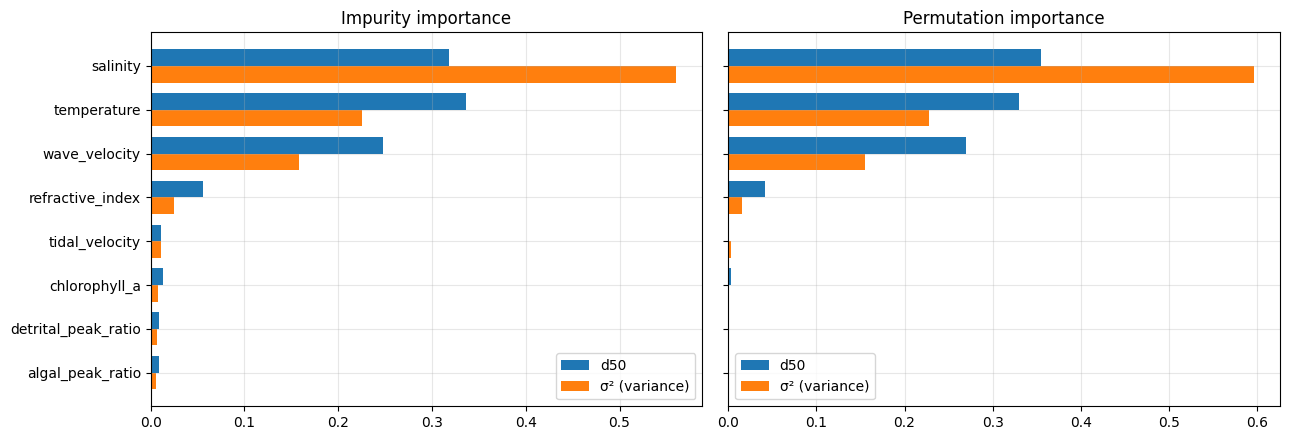

In [8]:
TOP_K = 4
SELECTED = imp["feature"].head(TOP_K).tolist()
print("Selected top-%d features:" % TOP_K, SELECTED)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
order = imp["feature"][::-1]
for ax, (col, title) in zip(axes, [("impurity", "Impurity importance"), ("permutation", "Permutation importance")]):
    vals = imp.set_index("feature").loc[order]
    h = 0.38; y = np.arange(len(order))
    ax.barh(y + h/2, vals[f"{col}_d50"], h, label="d50")
    ax.barh(y - h/2, vals[f"{col}_var"], h, label="σ² (variance)")
    ax.set_yticks(y); ax.set_yticklabels(order); ax.set_title(title); ax.legend()
plt.tight_layout(); plt.show()

## 8. Hyper-parameter tuning (training data only)
### 8.1 Random Forest: number of trees via out-of-bag (OOB) score
The OOB score is an internal validation estimate (each tree is scored on samples it did not train on), so it needs no extra validation set. We pick the smallest number of trees whose OOB R² is within 0.002 of the best value.

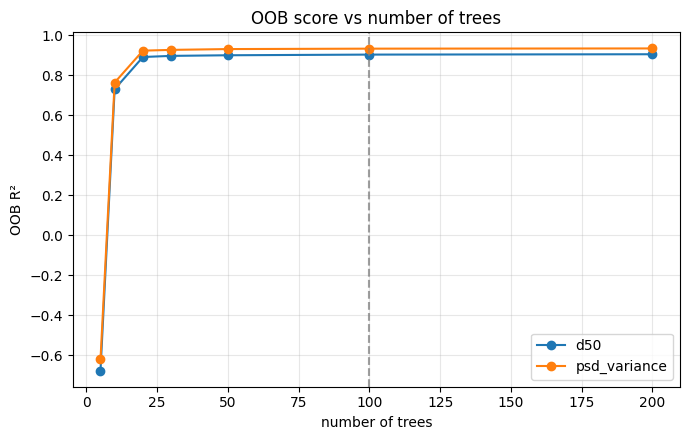

Chosen number of trees: {'d50': 100, 'psd_variance': 100}


In [9]:
TREE_GRID = [5, 10, 20, 30, 50, 100, 200]
oob = {t: [] for t in TARGETS}
for t in TARGETS:
    for n in TREE_GRID:
        rf = RandomForestRegressor(n_estimators=n, oob_score=True, random_state=SEED, n_jobs=-1)
        rf.fit(X_train[SELECTED], Y_train[t])
        oob[t].append(rf.oob_score_)

BEST_TREES = {}
for t in TARGETS:
    best = max(oob[t])
    BEST_TREES[t] = next(n for n, s in zip(TREE_GRID, oob[t]) if s >= best - 0.002)

plt.figure(figsize=(7, 4.5))
for t in TARGETS:
    plt.plot(TREE_GRID, oob[t], marker="o", label=t)
    plt.axvline(BEST_TREES[t], ls="--", alpha=0.5, color="gray")
plt.xlabel("number of trees"); plt.ylabel("OOB R²"); plt.title("OOB score vs number of trees"); plt.legend()
plt.tight_layout(); plt.show()
print("Chosen number of trees:", BEST_TREES)

### 8.2 SVR: `C`, `ε`, `γ` via 3-fold cross-validation
Features are standardised inside the pipeline, so there is no leakage from validation folds. The target is also standardised (`TransformedTargetRegressor`), which makes `ε` independent of the target's units.

In [12]:
param_grid = {
    "regressor__svr__C":       [1, 10, 100],
    "regressor__svr__epsilon": [0.1, 0.3],
    "regressor__svr__gamma":   ["scale", 0.1],
}
base_svr = TransformedTargetRegressor(
    regressor=make_pipeline(StandardScaler(), SVR(kernel="rbf", cache_size=1000)),
    transformer=StandardScaler(),
)
best_svr, svr_search = {}, {}
for t in TARGETS:
    gs = GridSearchCV(base_svr, param_grid, cv=KFold(3, shuffle=True, random_state=SEED),
                      scoring="r2", n_jobs=-1)
    gs.fit(X_train[SELECTED], Y_train[t])
    best_svr[t], svr_search[t] = gs.best_estimator_, gs
    print(f"{t:13s} best params: {gs.best_params_} | CV R2 = {gs.best_score_:.4f}")

d50           best params: {'regressor__svr__C': 10, 'regressor__svr__epsilon': 0.1, 'regressor__svr__gamma': 0.1} | CV R2 = 0.9196
psd_variance  best params: {'regressor__svr__C': 1, 'regressor__svr__epsilon': 0.1, 'regressor__svr__gamma': 0.1} | CV R2 = 0.9453


## 9. Final evaluation on the held-out test set
We compare three models for each target:
- **RF (all 8 features)**, 100 trees as the reference
- **RF (top-4, tuned)**
- **SVR (top-4, tuned)**

In [13]:
def metrics(y, p):
    return r2_score(y, p), mean_absolute_error(y, p), np.sqrt(mean_squared_error(y, p))

rf_all, rf_top = {}, {}
preds, rows = {}, []
for t in TARGETS:
    rf_all[t] = RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1).fit(X_train, Y_train[t])
    rf_top[t] = RandomForestRegressor(n_estimators=BEST_TREES[t], random_state=SEED, n_jobs=-1).fit(X_train[SELECTED], Y_train[t])
    preds[(t, "RF (all 8 features)")] = rf_all[t].predict(X_test)
    preds[(t, "RF (top-4, tuned)")]   = rf_top[t].predict(X_test[SELECTED])
    preds[(t, "SVR (top-4, tuned)")]  = best_svr[t].predict(X_test[SELECTED])
    for (tt, name), p in preds.items():
        if tt == t:
            r2, mae, rmse = metrics(Y_test[t], p)
            rows.append({"Target": t, "Model": name, "R2": r2, "MAE": mae, "RMSE": rmse})

results_df = pd.DataFrame(rows)
ceil = pd.Series(CEILING, name="Noise ceiling R2")
print("Noise ceiling (max achievable R2):", {k: round(v, 4) for k, v in CEILING.items()})
results_df.round(4)

Noise ceiling (max achievable R2): {'d50': 0.9303, 'psd_variance': 0.958}


,Target,Model,R2,MAE,RMSE
0,d50,RF (all 8 features),0.9138,10.8945,13.5454
1,d50,"RF (top-4, tuned)",0.9086,11.2398,13.9499
2,d50,"SVR (top-4, tuned)",0.9210,10.4890,12.9670
3,psd_variance,RF (all 8 features),0.9393,7.6517,9.5740
4,psd_variance,"RF (top-4, tuned)",0.9357,7.9783,9.8602
5,psd_variance,"SVR (top-4, tuned)",0.9481,7.1098,8.8558


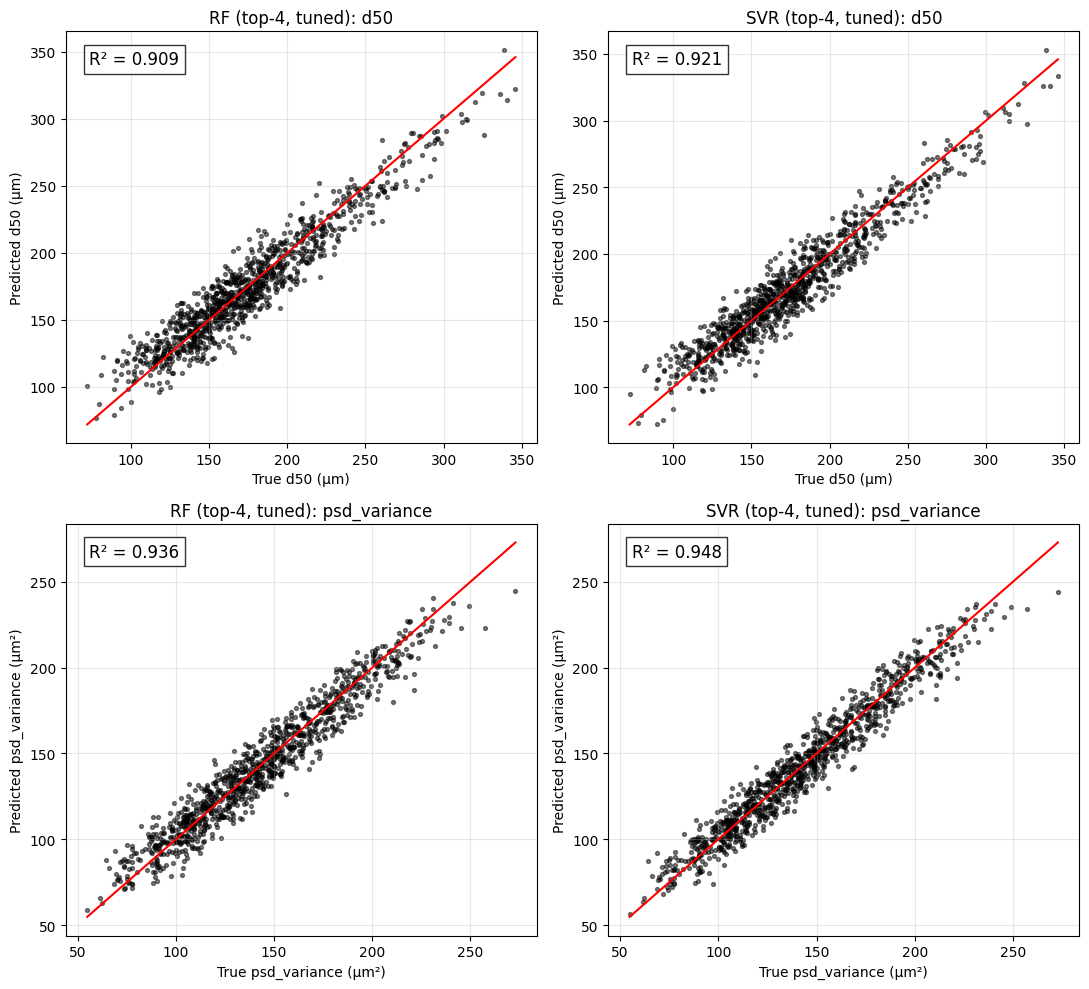

In [14]:
MODELS = ["RF (top-4, tuned)", "SVR (top-4, tuned)"]
UNITS = {"d50": "µm", "psd_variance": "µm²"}
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
for i, t in enumerate(TARGETS):
    y = Y_test[t].to_numpy()
    lo, hi = y.min(), y.max()
    for j, m in enumerate(MODELS):
        ax = axes[i, j]; p = preds[(t, m)]
        ax.scatter(y, p, s=8, alpha=0.5, c="k")
        ax.plot([lo, hi], [lo, hi], "r-", lw=1.5)
        ax.text(0.05, 0.92, f"R² = {r2_score(y, p):.3f}", transform=ax.transAxes, fontsize=12,
                bbox=dict(facecolor="white", alpha=0.8))
        ax.set_xlabel(f"True {t} ({UNITS[t]})"); ax.set_ylabel(f"Predicted {t} ({UNITS[t]})")
        ax.set_title(f"{m}: {t}")
plt.tight_layout(); plt.show()

### 9.1 Robustness check: 5-fold cross-validation on the full dataset

In [15]:
cv = KFold(5, shuffle=True, random_state=SEED)
cv_rows = []
for t in TARGETS:
    models = {
        "RF (top-4, tuned)": RandomForestRegressor(n_estimators=BEST_TREES[t], random_state=SEED, n_jobs=-1),
        "SVR (top-4, tuned)": best_svr[t],
    }
    for name, mdl in models.items():
        s = cross_validate(mdl, df[SELECTED], df[t], cv=cv,
                           scoring={"r2": "r2", "mae": "neg_mean_absolute_error",
                                    "rmse": "neg_root_mean_squared_error"})
        cv_rows.append({"Target": t, "Model": name, "Mean R2": s["test_r2"].mean(), "R2 std": s["test_r2"].std(),
                        "Mean MAE": -s["test_mae"].mean(), "Mean RMSE": -s["test_rmse"].mean()})
cv_df = pd.DataFrame(cv_rows)
cv_df.round(4)

,Target,Model,Mean R2,R2 std,Mean MAE,Mean RMSE
0,d50,"RF (top-4, tuned)",0.9052,0.0049,11.4055,14.2930
1,d50,"SVR (top-4, tuned)",0.9201,0.0017,10.4639,13.1282
2,psd_variance,"RF (top-4, tuned)",0.9340,0.0043,7.8959,9.8143
3,psd_variance,"SVR (top-4, tuned)",0.9464,0.0035,7.0803,8.8441


> **Note.** The SVR hyper-parameters were chosen on the training portion only, so the CV table above is a stability check, not an independent estimate. The held-out test table in Section 9 is the headline result.

## 10. Save outputs

In [16]:
results_df.to_csv("results/model_comparison_results.csv", index=False)
cv_df.to_csv("results/cross_validation_results.csv", index=False)
imp.to_csv("results/feature_importance.csv", index=False)
pd.DataFrame({
    "actual_d50": Y_test["d50"].to_numpy(),
    "pred_d50_rf": preds[("d50", "RF (top-4, tuned)")], "pred_d50_svr": preds[("d50", "SVR (top-4, tuned)")],
    "actual_psd_variance": Y_test["psd_variance"].to_numpy(),
    "pred_var_rf": preds[("psd_variance", "RF (top-4, tuned)")], "pred_var_svr": preds[("psd_variance", "SVR (top-4, tuned)")],
}).to_csv("results/test_predictions.csv", index=False)
joblib.dump({"rf": rf_top, "svr": best_svr, "features": SELECTED, "targets": TARGETS}, "results/trained_models.joblib")
print("Saved to ./results:", sorted(os.listdir("results")))

Saved to ./results: ['cross_validation_results.csv', 'feature_importance.csv', 'model_comparison_results.csv', 'test_predictions.csv', 'trained_models.joblib']


## 11. Conclusions

In [17]:
from IPython.display import Markdown
r = results_df.set_index(["Target", "Model"])["R2"]
def line(t):
    return (f"- **{t}**: RF top-4 R² = {r[(t,'RF (top-4, tuned)')]:.3f}, SVR top-4 R² = {r[(t,'SVR (top-4, tuned)')]:.3f}, "
            f"RF all-8 R² = {r[(t,'RF (all 8 features)')]:.3f}; noise ceiling = {CEILING[t]:.3f}.")
Markdown(f'''
**Results (test set, 1000 samples)**
{line("d50")}
{line("psd_variance")}

**Findings**
1. Both RF and SVR predict `d50` and σ² well. SVR is slightly better on this data. Its target functions are smooth, and an RBF kernel suits smooth surfaces better than piecewise-constant trees.
2. Top-4 features ({", ".join(SELECTED)}) lose almost nothing against all 8 features, so the four low-importance features can be dropped.
3. Both models are within about 0.02 R² of the **noise ceiling**, so they have learned essentially all the structure in the data. The remaining error is the noise we injected.

**Limitations (important)**
- The data is **synthetic**. The targets are artificial functions of the features, so these scores do **not** show that the models predict real sediment flocculation. The paper's real-data R² of 0.75–0.81 is lower because real measurements are noisier and the relationships are unknown.
- The features are independent and uniform. Real field measurements are correlated and time-dependent.
- Feature importance mostly reflects the coefficients we chose, so low-importance features are low by construction.
- Generalisation to other sites was not tested. The paper lists this as future work.
''')


**Results (test set, 1000 samples)**
- **d50**: RF top-4 R² = 0.909, SVR top-4 R² = 0.921, RF all-8 R² = 0.914; noise ceiling = 0.930.
- **psd_variance**: RF top-4 R² = 0.936, SVR top-4 R² = 0.948, RF all-8 R² = 0.939; noise ceiling = 0.958.

**Findings**
1. Both RF and SVR predict `d50` and σ² well. SVR is slightly better on this data. Its target functions are smooth, and an RBF kernel suits smooth surfaces better than piecewise-constant trees.
2. Top-4 features (salinity, temperature, wave_velocity, refractive_index) lose almost nothing against all 8 features, so the four low-importance features can be dropped.
3. Both models are within about 0.02 R² of the **noise ceiling**, so they have learned essentially all the structure in the data. The remaining error is the noise we injected.

**Limitations (important)**
- The data is **synthetic**. The targets are artificial functions of the features, so these scores do **not** show that the models predict real sediment flocculation. The paper's real-data R² of 0.75–0.81 is lower because real measurements are noisier and the relationships are unknown.
- The features are independent and uniform. Real field measurements are correlated and time-dependent.
- Feature importance mostly reflects the coefficients we chose, so low-importance features are low by construction.
- Generalisation to other sites was not tested. The paper lists this as future work.
